# ♻️ PreZero / Fillinq Challenge: AI-Driven Smart Waste Routing
### **Municipal Glass Recycling Optimization for the City of Heilbronn**
*Hackathon Roadmap, Exploratory Data Analysis, Pattern Recognition & Dynamic Routing Architecture*

---

### 📌 1. Challenge Context & Background
Like many municipalities, the **City of Heilbronn** faces the operational and environmental challenge of collecting municipal waste efficiently while keeping the city spotless and preventing overflowing containers.

* **The Baseline Status Quo:** Waste containers are emptied on a **fixed calendar schedule** area by area, regardless of their actual fill level (*"you drive past there anyway"*). Consequently:
  * Many containers are emptied when they are **under-filled** (< 40–50%), wasting fuel, labor, truck wear, and emitting unnecessary $CO_2$.
  * High-traffic containers sit **overfilled** for days or weeks before scheduled pickup, leading to littering, glass breakage on pavements, and citizen dissatisfaction.
* **The Fillinq Opportunity:** PreZero's pragmatic solution **Fillinq** captures empirical fill levels. With over a year of real-world historical data, our mission is to build the AI intelligence layer on top of this data.
* **The Goal:** 
  1. Uncover consumption patterns, material differences, and seasonal impacts.
  2. Group containers by behavioral profile.
  3. Define the operational variables (vehicle capacity, waste density, shift rules, distances).
  4. Design a dynamic route optimization engine to replace rigid schedules with smart, demand-driven collections.


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Visual styling setup
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['figure.dpi'] = 110
warnings.filterwarnings('ignore')

# Seed for reproducibility
np.random.seed(42)

# Standard material color palette
MAT_COLORS = {'white': '#1f77b4', 'green': '#2ca02c', 'brown': '#8c564b'}

print("Libraries imported successfully!")
print(f"Pandas version: {pd.__version__}")


Libraries imported successfully!
Pandas version: 3.1.1


---
## 📥 2. Data Ingestion, Sanitization & Location Identification

### 📍 Understanding `Location_id` & The Exact Coordinates Question
Notice that in `glass_fill_levels_anonymized_f.csv`, the location column contains UUID strings (e.g., `0004c095-29ec-4894-81a8-05f3a7a55650`) rather than latitude, longitude, or street addresses.
* **Why?** The dataset filename explicitly states **`anonymized`**. The challenge organizers intentionally replaced real physical coordinates with unique identifiers for competition privacy and benchmarking.
* **Can we get the exact GPS coordinates?**
  * **Option A (Ask the Mentors on Site):** In **Section 6** of the challenge brief, the organizer states:
    > *"I will be present at HHN throughout the weekend. Feel free to reach out anytime if you have questions or need additional data."*
    You can directly ask the PreZero / Fillinq mentors at HHN for the un-anonymized coordinate mapping table (`Location_id` $\leftrightarrow$ `Latitude, Longitude, Street Address`).
  * **Option B (Synthetic Coordinate Simulation for Routing):** For building and testing the route optimization engine (Section 3 of the brief: *Inter-Point Distances, Disposal Depot Proximity, Depot Distances*), we generate a realistic synthetic coordinate grid bounded within the geographical footprint of the **City of Heilbronn** ($49.11^\circ\text{N} - 49.18^\circ\text{N}, 9.17^\circ\text{E} - 9.26^\circ\text{E}$). Once real coordinates are provided, swapping them into our routing pipeline takes one line of code!

### 🧹 Data Cleaning Pipeline:
1. Strip UTF-8 BOM (`\ufeff`) from column names.
2. Handle the `'overfull'` category: preserve `is_overfull` boolean and assign `fill_num = 110.0%` for quantitative volume modeling.
3. Chronological ordering per location and material stream.


In [2]:
DATA_PATH = "glass_fill_levels_anonymized_f.csv"

def load_and_clean_dataset(filepath: str) -> pd.DataFrame:
    """
    Loads, cleans, and enriches the glass container fill level dataset.
    """
    df = pd.read_csv(filepath, encoding='utf-8-sig')
    
    # Strip any potential BOM or whitespace from column names
    df.columns = [c.strip().replace('\ufeff', '') for c in df.columns]
    
    # Parse date
    df['date'] = pd.to_datetime(df['date'])
    
    # Create clean numeric fill percentage and binary overfull indicator
    df['is_overfull'] = df['fill_level_perc'].astype(str).str.strip().str.lower() == 'overfull'
    df['fill_num'] = df['fill_level_perc'].apply(lambda x: 110.0 if str(x).strip().lower() == 'overfull' else float(x))
    
    # Sort chronologically by location, material, and date
    df = df.sort_values(by=['Location_id', 'material_type', 'date']).reset_index(drop=True)
    
    # Add calendar features
    df['year_month'] = df['date'].dt.to_period('M')
    df['day_name'] = df['date'].dt.day_name()
    df['day_of_week'] = df['date'].dt.dayofweek
    df['week_number'] = df['date'].dt.isocalendar().week
    
    return df

df = load_and_clean_dataset(DATA_PATH)
print(f"Data successfully loaded: {len(df):,} total records.")
display(df.head(6))


Data successfully loaded: 11,701 total records.


,Location_id,material_type,date,fill_level_perc,is_overfull,fill_num,year_month,day_name,day_of_week,week_number
0,0004c095-29ec-4894-81a8-05f3a7a55650,brown,2025-10-31,100,False,100.0,2025-10,Friday,4,44
1,0004c095-29ec-4894-81a8-05f3a7a55650,brown,2025-12-08,40,False,40.0,2025-12,Monday,0,50
2,0004c095-29ec-4894-81a8-05f3a7a55650,brown,2025-12-23,80,False,80.0,2025-12,Tuesday,1,52
3,0004c095-29ec-4894-81a8-05f3a7a55650,brown,2026-02-25,60,False,60.0,2026-02,Wednesday,2,9
4,0004c095-29ec-4894-81a8-05f3a7a55650,brown,2026-04-14,100,False,100.0,2026-04,Tuesday,1,16
5,0004c095-29ec-4894-81a8-05f3a7a55650,brown,2026-05-18,100,False,100.0,2026-05,Monday,0,21


In [3]:
def generate_synthetic_heilbronn_coordinates(location_ids: list, seed: int = 42) -> pd.DataFrame:
    """
    Generates realistic synthetic GPS coordinates within the City of Heilbronn bounding box.
    Heilbronn Bounding Box:
      Latitude:  49.115 to 49.180 N
      Longitude:  9.170 to 9.255 E
    """
    rng = np.random.default_rng(seed)
    n = len(location_ids)
    
    # Center around Heilbronn center with realistic urban clustering
    center_lat, center_lon = 49.1427, 9.2109
    lats = center_lat + rng.normal(0, 0.022, n).clip(-0.035, 0.035)
    lons = center_lon + rng.normal(0, 0.025, n).clip(-0.040, 0.040)
    
    coords_df = pd.DataFrame({
        'Location_id': location_ids,
        'simulated_latitude': lats.round(6),
        'simulated_longitude': lons.round(6)
    })
    return coords_df

unique_locs = df['Location_id'].unique().tolist()
loc_coords_df = generate_synthetic_heilbronn_coordinates(unique_locs)
print(f"Simulated geographic coordinates generated for all {len(loc_coords_df)} unique bin locations:")
display(loc_coords_df.head(5))


Simulated geographic coordinates generated for all 449 unique bin locations:


,Location_id,simulated_latitude,simulated_longitude
0,0004c095-29ec-4894-81a8-05f3a7a55650,49.149404,9.220484
1,0058ed93-88f5-4c25-8746-2e5ee87e5559,49.119820,9.207622
2,009c98f3-c93a-4d55-abfe-79f7acf2a0ff,49.159210,9.219619
3,00e9e2cf-b6f7-4872-908b-fcf4c35f388a,49.163392,9.250900
4,01371af2-75b4-4b9a-9e74-be20129483d5,49.107700,9.250900


In [4]:
# Summary Statistics Table
n_records = len(df)
n_locations = df['Location_id'].nunique()
n_dates = df['date'].nunique()
min_date = df['date'].min().strftime('%Y-%m-%d')
max_date = df['date'].max().strftime('%Y-%m-%d')
span_days = (df['date'].max() - df['date'].min()).days
n_overfull = df['is_overfull'].sum()
pct_overfull = (n_overfull / n_records) * 100

summary_df = pd.DataFrame({
    'Metric': [
        'Total Recorded Readings',
        'Unique Container Locations',
        'Distinct Observation Dates',
        'Date Span Start',
        'Date Span End',
        'Total Duration (Days)',
        'Average Readings per Location',
        'Total Overfull Events',
        'Global Overfull Rate (%)',
        'Missing Values (Nulls)'
    ],
    'Value': [
        f"{n_records:,}",
        f"{n_locations}",
        f"{n_dates}",
        min_date,
        max_date,
        f"{span_days} days (~{span_days/30.4:.1f} months)",
        f"{n_records / n_locations:.1f}",
        f"{n_overfull:,}",
        f"{pct_overfull:.2f}%",
        f"{df.isnull().sum().sum()} (Zero nulls)"
    ]
})

print("=" * 60)
print("      DATASET HEALTH CHECK & CORE KPI SUMMARY")
print("=" * 60)
display(summary_df)


      DATASET HEALTH CHECK & CORE KPI SUMMARY


,Metric,Value
0,Total Recorded Readings,"11,701"
1,Unique Container Locations,449
2,Distinct Observation Dates,229
3,Date Span Start,2025-10-17
4,Date Span End,2026-09-30
5,Total Duration (Days),348 days (~11.4 months)
6,Average Readings per Location,26.1
7,Total Overfull Events,"1,192"
8,Global Overfull Rate (%),10.19%
9,Missing Values (Nulls),0 (Zero nulls)


---
## 📊 3. Exploratory Data Analysis & Overall Distributions

Let's look at the overall distribution of fill levels and the proportion of readings across the three glass categories: **Brown**, **Green**, and **White**.


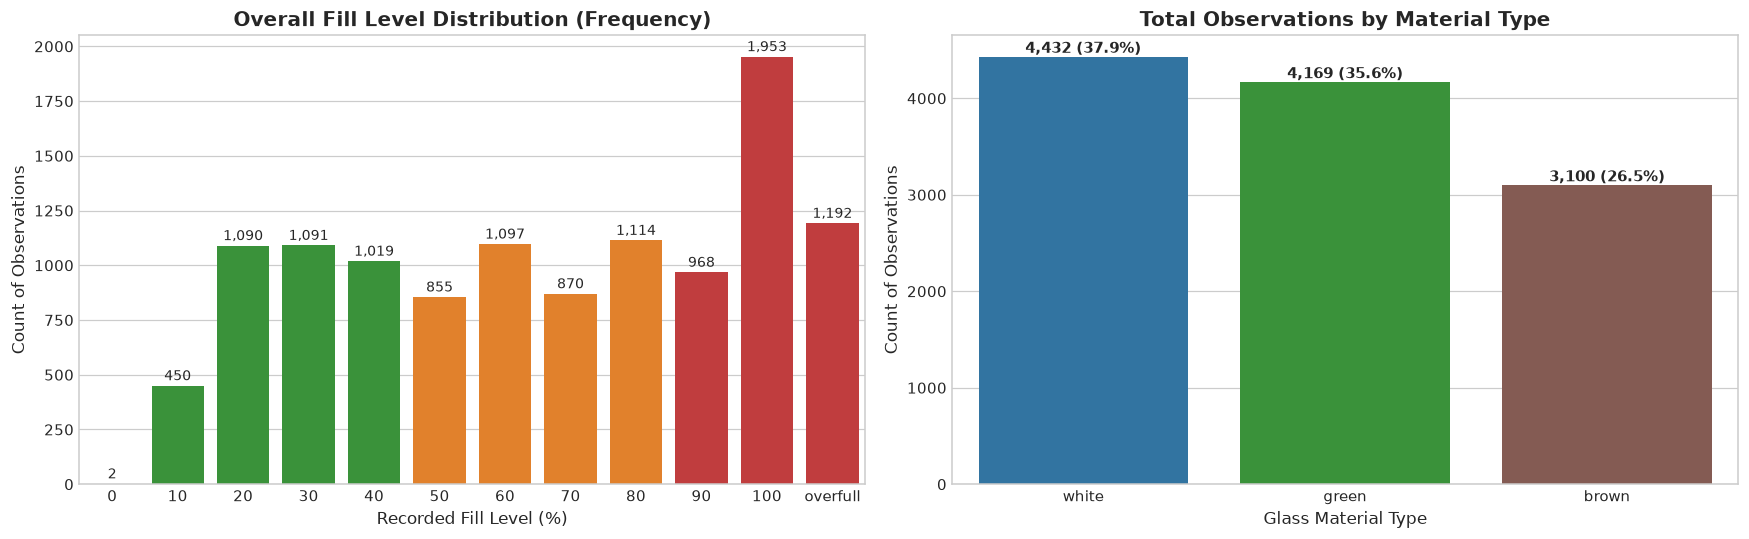

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Fill Level Distribution
fl_counts = df['fill_level_perc'].value_counts()
ordered_cats = ['0', '10', '20', '30', '40', '50', '60', '70', '80', '90', '100', 'overfull']
fl_ordered = fl_counts.reindex(ordered_cats)

bar_colors = ['#2ca02c' if c in ['10', '20', '30', '40'] else '#ff7f0e' if c in ['50', '60', '70', '80'] else '#d62728' for c in ordered_cats]

sns.barplot(x=fl_ordered.index, y=fl_ordered.values, ax=axes[0], palette=bar_colors)
axes[0].set_title("Overall Fill Level Distribution (Frequency)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Recorded Fill Level (%)", fontsize=11)
axes[0].set_ylabel("Count of Observations", fontsize=11)
for i, v in enumerate(fl_ordered.values):
    axes[0].text(i, v + 25, f"{v:,}", ha='center', fontsize=9)

# 2. Material Breakdown
mat_counts = df['material_type'].value_counts()
sns.barplot(x=mat_counts.index, y=mat_counts.values, ax=axes[1], palette=[MAT_COLORS[m] for m in mat_counts.index])
axes[1].set_title("Total Observations by Material Type", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Glass Material Type", fontsize=11)
axes[1].set_ylabel("Count of Observations", fontsize=11)
for i, (m, v) in enumerate(mat_counts.items()):
    axes[1].text(i, v + 40, f"{v:,} ({v/len(df)*100:.1f}%)", ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


---
## 📈 4. Dedicated Trajectory Analysis for Each Glass Type (Oct 2025 – Sep 2026)

To clearly see **what we are dealing with** for each specific glass category, we plot **3 dedicated time-series figures** (one for **White Glass**, one for **Green Glass**, and one for **Brown Glass**) across the entire 348-day duration of the dataset.

Each plot illustrates:
1. **The Network-Wide Daily Mean Fill Level** (bold solid line).
2. **The Interquartile Range Corridor (25th to 75th percentile)** (shaded envelope showing network variance).
3. **Real Individual Container Trajectories** (dashed lines with markers) demonstrating the actual **sawtooth fill-and-empty cycles** of specific bins.
4. **Key Operational Thresholds:**
   * **80% Target Servicing Threshold** (Orange dotted line)
   * **100% Rated Volume Capacity** (Red dotted line)
   * **110% Overfull Alert Level** (Dark red dashed line)


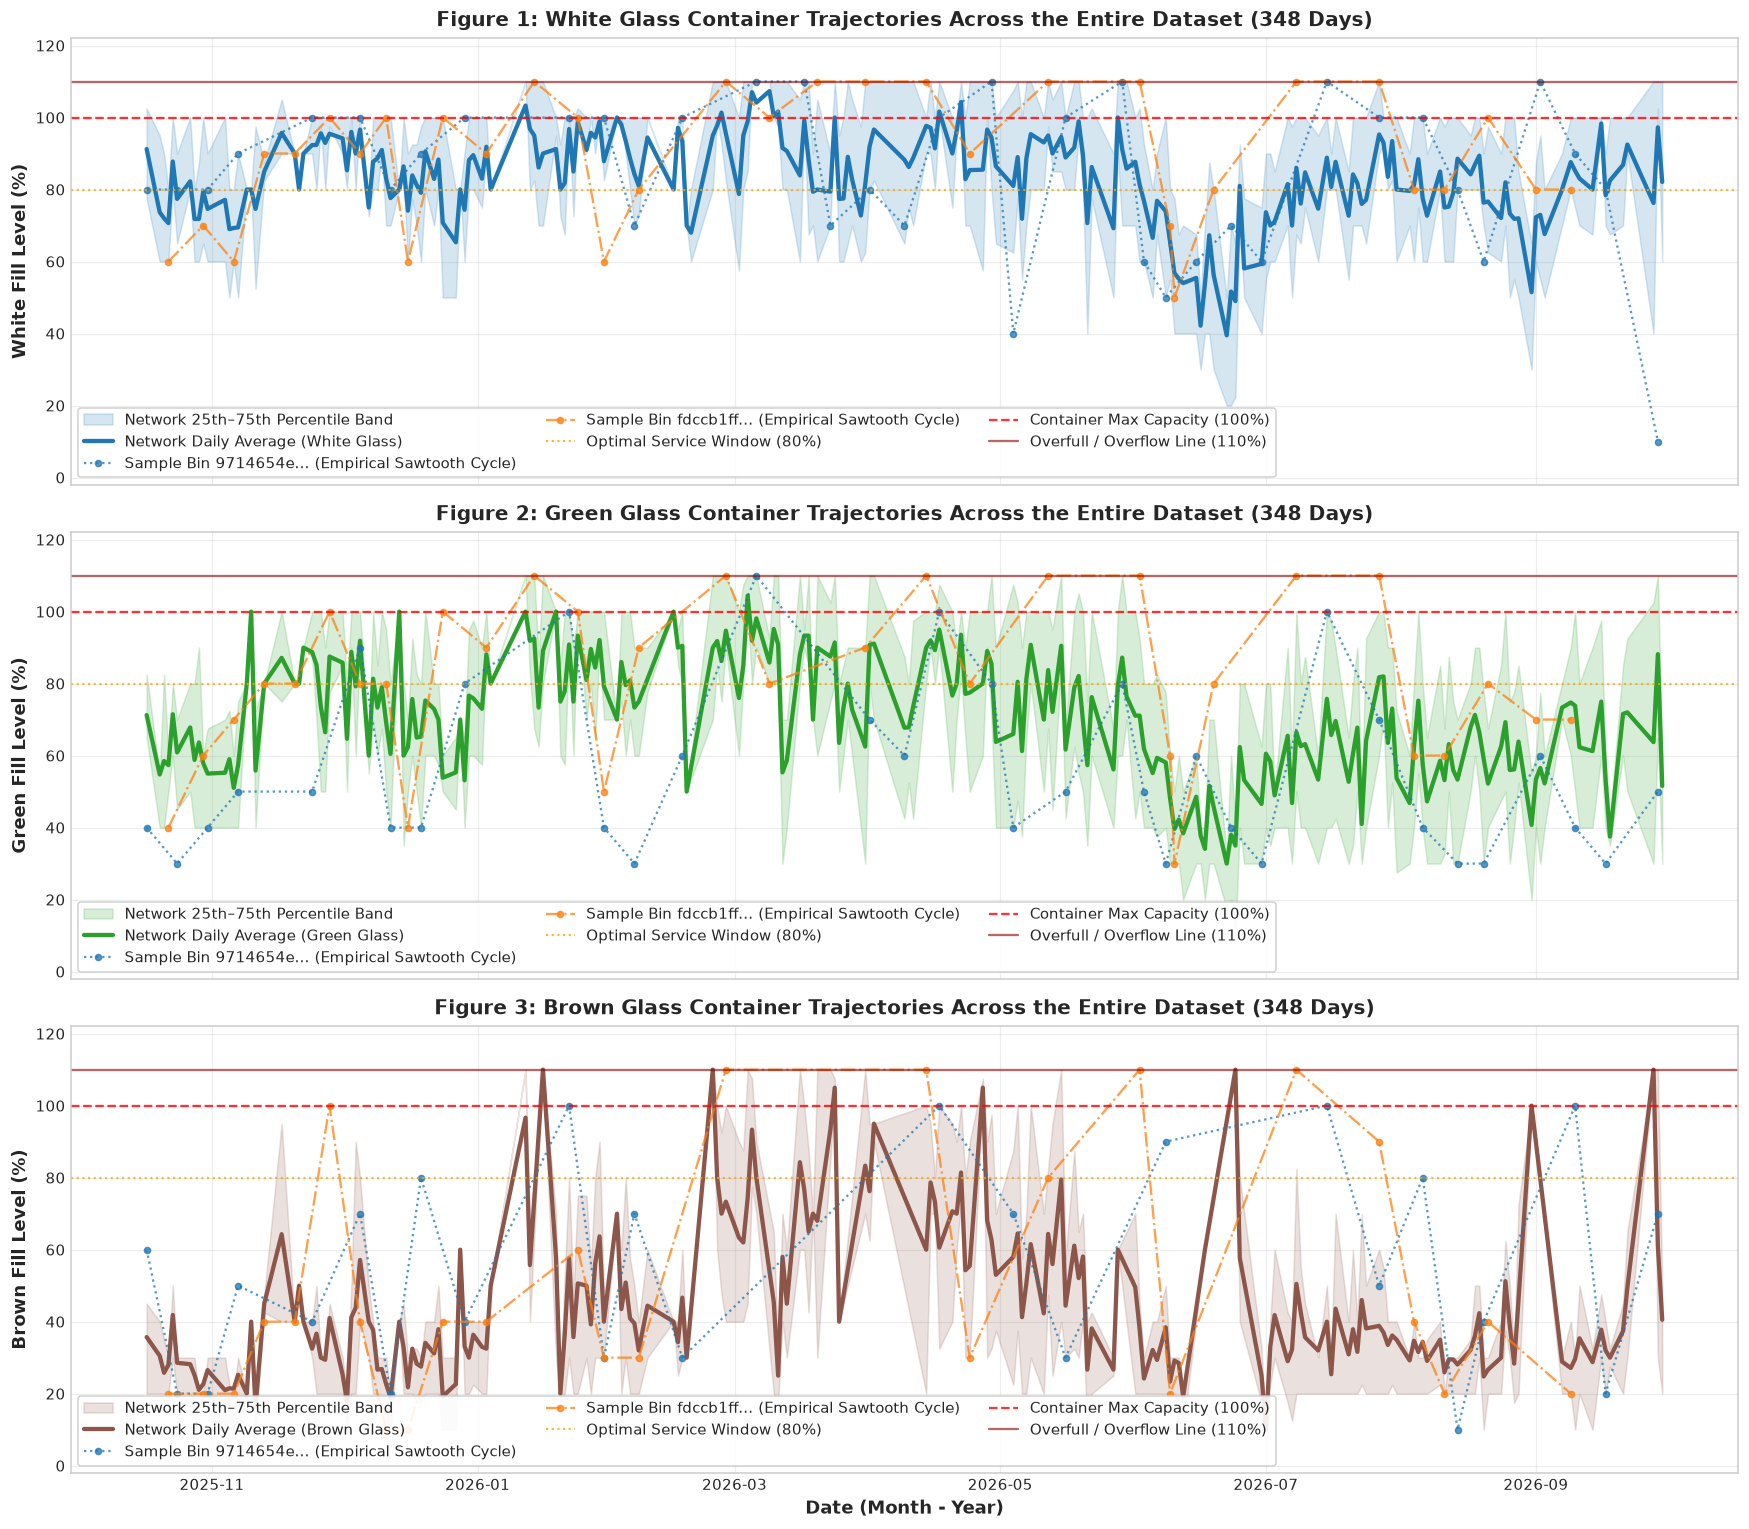

In [6]:
# High-observation locations to display real container sawtooth cycles
sample_bins = [
    '9714654e-0a2e-4a86-87d5-426a6a2651eb',
    'fdccb1ff-bce6-4e0f-842d-305a11a8de2e',
    'eecbf6fa-decf-46da-b110-bf014e7c181d'
]

fig, axes = plt.subplots(3, 1, figsize=(16, 14), sharex=True)

for idx, mat in enumerate(['white', 'green', 'brown']):
    ax = axes[idx]
    m_df = df[df['material_type'] == mat]
    
    # Calculate daily statistics
    daily_stats = m_df.groupby('date')['fill_num'].agg(
        mean='mean',
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75)
    )
    
    # 1. Shaded IQR Corridor (Middle 50% of the network)
    ax.fill_between(daily_stats.index, daily_stats['q25'], daily_stats['q75'], 
                    color=MAT_COLORS[mat], alpha=0.18, label=f'Network 25th–75th Percentile Band')
    
    # 2. Daily Network Average Line
    ax.plot(daily_stats.index, daily_stats['mean'], color=MAT_COLORS[mat], 
            linewidth=2.8, label=f'Network Daily Average ({mat.capitalize()} Glass)')
    
    # 3. Plot real sample container cycles
    line_styles = [':', '-.', '--']
    for l_idx, bin_id in enumerate(sample_bins[:2]):
        bin_data = m_df[m_df['Location_id'] == bin_id].sort_values('date')
        if len(bin_data) > 6:
            ax.plot(bin_data['date'], bin_data['fill_num'], linestyle=line_styles[l_idx], 
                    alpha=0.75, marker='o', markersize=4, 
                    label=f'Sample Bin {bin_id[:8]}... (Empirical Sawtooth Cycle)')
    
    # 4. Reference lines
    ax.axhline(80, color='orange', linestyle=':', linewidth=1.4, alpha=0.8, label='Optimal Service Window (80%)')
    ax.axhline(100, color='red', linestyle='--', linewidth=1.5, alpha=0.8, label='Container Max Capacity (100%)')
    ax.axhline(110, color='darkred', linestyle='-', linewidth=1.5, alpha=0.6, label='Overfull / Overflow Line (110%)')
    
    ax.set_ylim(-2, 122)
    ax.set_ylabel(f'{mat.capitalize()} Fill Level (%)', fontsize=12, fontweight='bold')
    ax.set_title(f'Figure {idx+1}: {mat.capitalize()} Glass Container Trajectories Across the Entire Dataset (348 Days)', 
                 fontsize=13, fontweight='bold', pad=8)
    ax.legend(loc='lower left', ncol=3, fontsize=9.5, frameon=True, facecolor='white', framealpha=0.9)
    ax.grid(True, alpha=0.35)

axes[2].set_xlabel("Date (Month - Year)", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


### 🔍 What the 3 Plots Reveal:
1. **White Glass (Weißglas — Top Plot):**
   * **Chronic High Fill:** The network average hovers between **80% and 95%** for most of the year.
   * **Constant Overflow Crisis:** In Spring 2026, the 75th percentile line hits the **110% Overfull** ceiling.
   * **Rapid Sawtooth Cycles:** Looking at individual bin trajectories (e.g., `9714654e...`), once emptied down to 40-70%, white glass rapidly shoots back up to 100% within 2 to 3 weeks.
2. **Green Glass (Grünglas — Middle Plot):**
   * **Balanced Accumulation:** Network average fluctuates between **60% and 85%**.
   * **Clear Holiday Impact:** Visible elevation during the December/January holiday entertaining season.
   * Individual cycles show steady, predictable accumulation over 3-4 week windows.
3. **Brown Glass (Braunglas — Bottom Plot):**
   * **Persistent Underutilization:** Network average stays between **30% and 55%**.
   * The 25th percentile line is frequently at **10% to 20%**.
   * Emptyings frequently happen when brown containers are only 20%–40% full simply because the truck was on-site emptying the white container!


In [7]:
# Stream Metrics Comparison Table
mat_stats = []
for mat in ['white', 'green', 'brown']:
    sub = df[df['material_type'] == mat]
    mat_stats.append({
        'Material Stream': mat.capitalize() + ' Glass',
        'Total Readings': f"{len(sub):,}",
        'Mean Fill (%)': f"{sub['fill_num'].mean():.1f}%",
        'Median Fill (%)': f"{sub['fill_num'].median():.1f}%",
        'Overfull Count': f"{sub['is_overfull'].sum():,}",
        'Overfull Rate (%)': f"{sub['is_overfull'].mean() * 100:.1f}%",
        'At or Above Capacity (>=100%)': f"{(sub['fill_num'] >= 100).mean() * 100:.1f}%",
        'Underfilled (<=30%)': f"{(sub['fill_num'] <= 30).mean() * 100:.1f}%"
    })

stream_comparison_df = pd.DataFrame(mat_stats).set_index('Material Stream')
print("=" * 85)
print("             COMPREHENSIVE GLASS STREAM OPERATIONAL BENCHMARK")
print("=" * 85)
display(stream_comparison_df)


             COMPREHENSIVE GLASS STREAM OPERATIONAL BENCHMARK


,Total Readings,Mean Fill (%),Median Fill (%),Overfull Count,Overfull Rate (%),At or Above Capacity (>=100%),Underfilled (<=30%)
Material Stream,,,,,,,
White Glass,"4,432",82.2%,90.0%,731,16.5%,42.2%,4.8%
Green Glass,"4,169",68.1%,70.0%,357,8.6%,24.7%,14.7%
Brown Glass,"3,100",40.0%,30.0%,104,3.4%,7.9%,58.4%


---
## 📅 5. Temporal Dynamics, Seasonality & External Drivers

The challenge prompts:
> *"How do events like school vacations, public holidays (e.g., Christmas, Easter, Pentecost), or seasonal shifts impact waste volume?"*

Let's examine network-wide monthly dynamics and overflow incident rates.


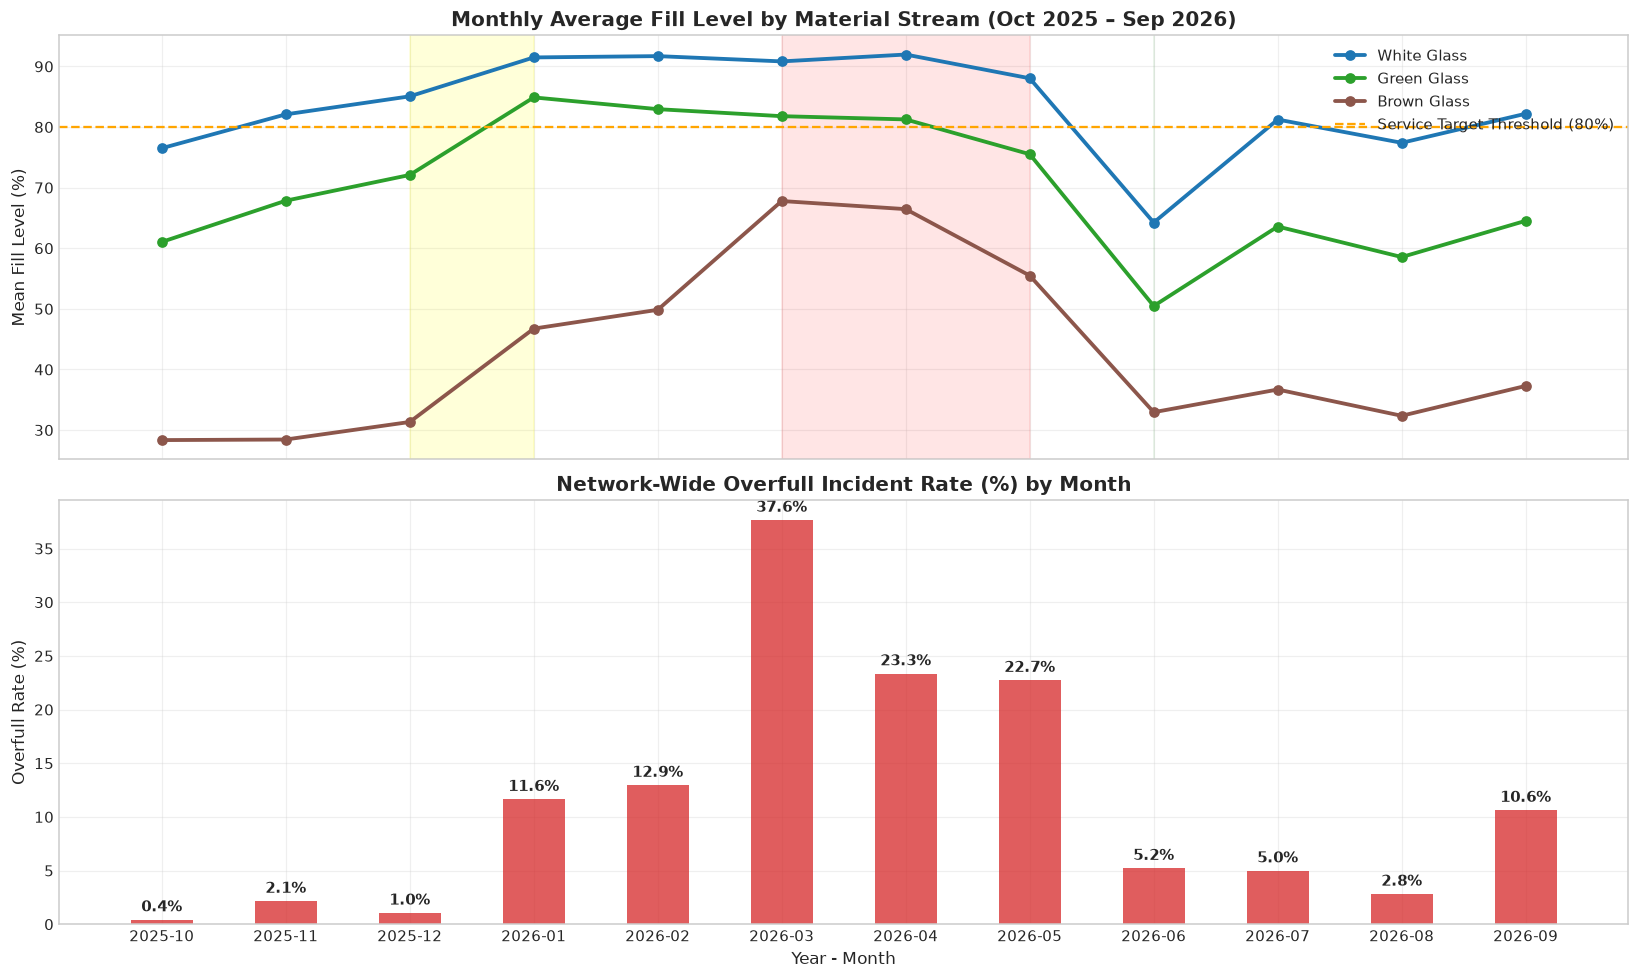

In [8]:
# Monthly aggregation
monthly_mean = df.pivot_table(index='year_month', columns='material_type', values='fill_num', aggfunc='mean')
monthly_overfull = df.groupby('year_month')['is_overfull'].mean() * 100

fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

# 1. Monthly Mean Fill Levels
for mat in ['white', 'green', 'brown']:
    axes[0].plot(monthly_mean.index.astype(str), monthly_mean[mat], marker='o', linewidth=2.5, 
                 label=f"{mat.capitalize()} Glass", color=MAT_COLORS[mat])
axes[0].axhline(80, color='orange', linestyle='--', label='Service Target Threshold (80%)')
axes[0].set_title("Monthly Average Fill Level by Material Stream (Oct 2025 – Sep 2026)", fontsize=13, fontweight='bold')
axes[0].set_ylabel("Mean Fill Level (%)", fontsize=11)
axes[0].legend(loc='upper right')
axes[0].grid(True, alpha=0.3)

# Shading key periods
axes[0].axvspan('2025-12', '2026-01', color='yellow', alpha=0.15, label='Holiday Season (Christmas/Silvester)')
axes[0].axvspan('2026-03', '2026-05', color='red', alpha=0.10, label='Spring Backlog Surge (Easter/Pfingsten)')
axes[0].axvspan('2026-06', '2026-06', color='green', alpha=0.10, label='Summer Fleet Sweep')

# 2. Monthly Overfull Rate
axes[1].bar(monthly_overfull.index.astype(str), monthly_overfull.values, color='#d62728', alpha=0.75, width=0.5)
axes[1].set_title("Network-Wide Overfull Incident Rate (%) by Month", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Year - Month", fontsize=11)
axes[1].set_ylabel("Overfull Rate (%)", fontsize=11)
axes[1].grid(True, alpha=0.3)

for i, v in enumerate(monthly_overfull.values):
    axes[1].text(i, v + 0.8, f"{v:.1f}%", ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


---
## 📉 6. Inefficiency Diagnosis: Baseline Emptying Audit

Under a fixed-schedule regime, containers are emptied because *"it's Thursday in District B"*, not because they need it.
We can identify historical emptying events by detecting sudden drops in fill level between consecutive observations:
$$\text{Emptying Detected when: } \text{Fill}_{t} < \text{Fill}_{t-1}$$

Let's evaluate the operational state of containers **immediately prior to being emptied**:
* **Late / Overdue Emptying ($\ge 100\%$):** Bin overflow, ground litter, public hygiene hazard.
* **Optimal Emptying (70% – 90%):** High collection efficiency without citizen complaints.
* **Premature Emptying (< 50%):** Wasted stop, wasted driver time, fuel consumed for minimal payload.


Total historical emptying events captured: 4,266
       EMPTYING EFFICIENCY AUDIT (PRE-EMPTYING FILL LEVELS)


,Count,Percentage (%)
efficiency_class,,
Late / Overflow (>=100%),1895,44.4
Optimal Window (70-90%),1253,29.4
Premature (40-60%),788,18.5
Highly Inefficient (<40%),330,7.7


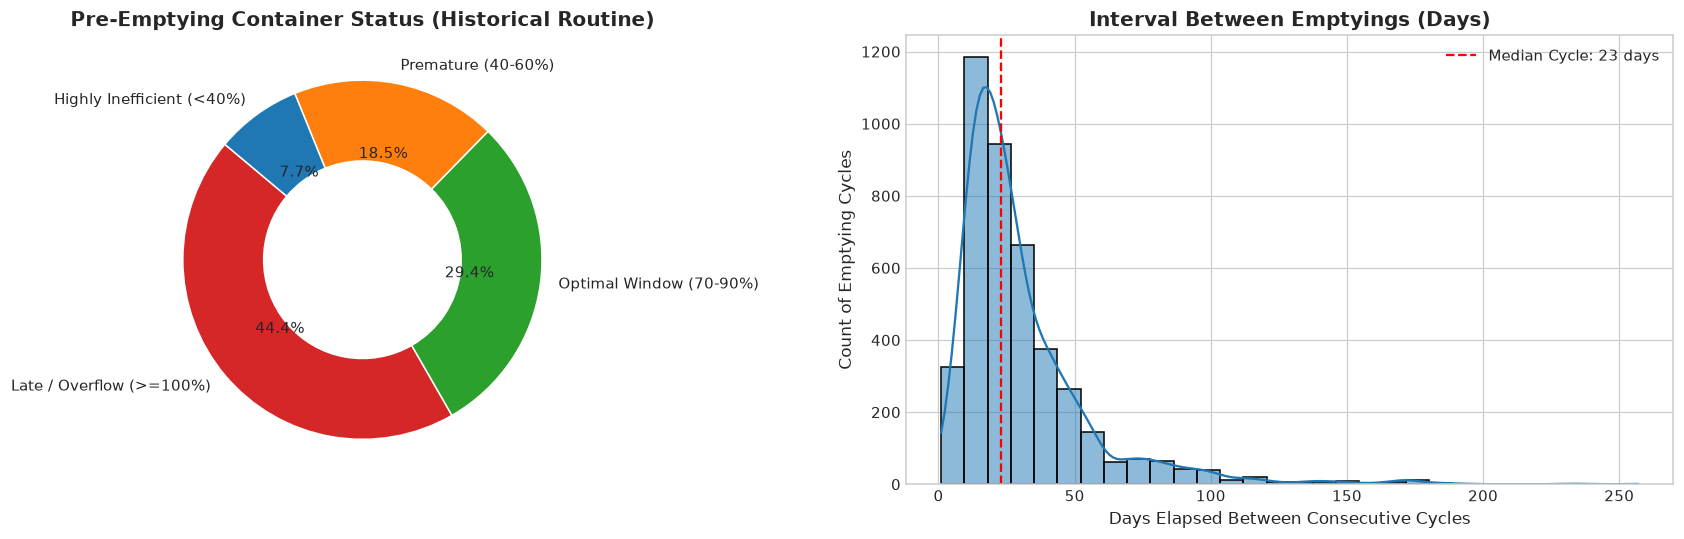

In [9]:
# Compute sequential changes per container
df['prev_date'] = df.groupby(['Location_id', 'material_type'])['date'].shift(1)
df['prev_fill'] = df.groupby(['Location_id', 'material_type'])['fill_num'].shift(1)
df['days_diff'] = (df['date'] - df['prev_date']).dt.days
df['fill_diff'] = df['fill_num'] - df['prev_fill']

# Emptyings occur when fill level drops
emptying_events = df[df['fill_diff'] < 0].copy()

def classify_emptying_efficiency(prev_val):
    if prev_val >= 100:
        return 'Late / Overflow (>=100%)'
    elif prev_val >= 70:
        return 'Optimal Window (70-90%)'
    elif prev_val >= 40:
        return 'Premature (40-60%)'
    else:
        return 'Highly Inefficient (<40%)'

emptying_events['efficiency_class'] = emptying_events['prev_fill'].apply(classify_emptying_efficiency)

class_dist = emptying_events['efficiency_class'].value_counts()
class_pct = emptying_events['efficiency_class'].value_counts(normalize=True) * 100

print(f"Total historical emptying events captured: {len(emptying_events):,}")
print("=" * 65)
print("       EMPTYING EFFICIENCY AUDIT (PRE-EMPTYING FILL LEVELS)")
print("=" * 65)
eff_df = pd.DataFrame({'Count': class_dist, 'Percentage (%)': class_pct.round(1)})
display(eff_df)

# Plotting Emptying Efficiency
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

eff_colors = {'Late / Overflow (>=100%)': '#d62728', 'Optimal Window (70-90%)': '#2ca02c', 
              'Premature (40-60%)': '#ff7f0e', 'Highly Inefficient (<40%)': '#1f77b4'}
wedges, texts, autotexts = axes[0].pie(
    class_pct, labels=class_pct.index, autopct='%1.1f%%', startangle=140,
    colors=[eff_colors[k] for k in class_pct.index],
    wedgeprops=dict(width=0.45, edgecolor='w')
)
axes[0].set_title("Pre-Emptying Container Status (Historical Routine)", fontsize=13, fontweight='bold')

sns.histplot(emptying_events['days_diff'].dropna(), bins=30, kde=True, ax=axes[1], color='#1f77b4')
axes[1].set_title("Interval Between Emptyings (Days)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Days Elapsed Between Consecutive Cycles", fontsize=11)
axes[1].set_ylabel("Count of Emptying Cycles", fontsize=11)
axes[1].axvline(emptying_events['days_diff'].median(), color='red', linestyle='--', 
                label=f"Median Cycle: {emptying_events['days_diff'].median():.0f} days")
axes[1].legend()

plt.tight_layout()
plt.show()


---
## 🏷️ 7. Container Profiling & Behavioral Clustering

Using **K-Means clustering**, we group the 449 locations into 4 operational tiers based on throughput, overflow propensity, and daily accumulation speed.


          OPERATIONAL CLUSTER PROFILES (449 CONTAINER LOCATIONS)


,Container_Count,Mean_Fill_Level,Avg_Overfull_Rate,Daily_Fill_Rate_Pct
Tier,,,,
Tier 1: Chronic Overflow Hotspot,2,110.00,100.00,0.83
Tier 2: High-Volume Steady,149,71.35,14.01,1.41
Tier 3: Moderate Regular,225,63.01,7.58,0.69
Tier 4: Low-Volume Sporadic,73,48.65,1.58,0.52


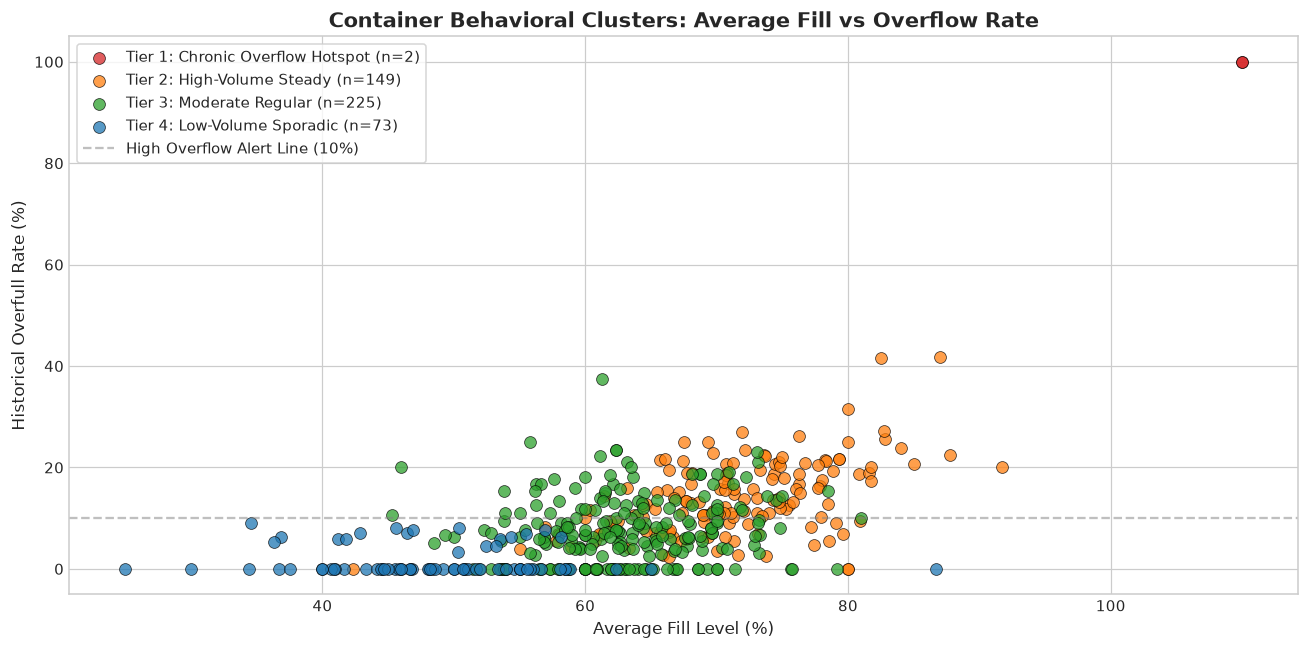

In [10]:
# 1. Compute accumulation daily rates (where fill level increases)
accum_df = df[df['fill_diff'] > 0].copy()
accum_df['daily_rate'] = accum_df['fill_diff'] / accum_df['days_diff']

# 2. Location-level feature engineering
loc_features = df.groupby('Location_id').agg(
    mean_fill=('fill_num', 'mean'),
    std_fill=('fill_num', 'std'),
    overfull_rate=('is_overfull', lambda x: x.mean() * 100),
    total_obs=('fill_num', 'count')
)

loc_rates = accum_df.groupby('Location_id')['daily_rate'].mean().rename('avg_daily_rate')
loc_features = loc_features.join(loc_rates).fillna({'avg_daily_rate': loc_rates.median(), 'std_fill': 0})

# 3. K-Means Clustering
features_for_clustering = ['mean_fill', 'overfull_rate', 'avg_daily_rate', 'std_fill']
scaler = StandardScaler()
X_scaled = scaler.fit_transform(loc_features[features_for_clustering])

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
loc_features['Cluster'] = kmeans.fit_predict(X_scaled)

# Name clusters based on centroids
cluster_profile = loc_features.groupby('Cluster')[features_for_clustering].mean()

cluster_map = {}
for cl in cluster_profile.index:
    mf = cluster_profile.loc[cl, 'mean_fill']
    ofr = cluster_profile.loc[cl, 'overfull_rate']
    if ofr > 15:
        cluster_map[cl] = 'Tier 1: Chronic Overflow Hotspot'
    elif mf > 65:
        cluster_map[cl] = 'Tier 2: High-Volume Steady'
    elif mf > 50:
        cluster_map[cl] = 'Tier 3: Moderate Regular'
    else:
        cluster_map[cl] = 'Tier 4: Low-Volume Sporadic'

loc_features['Tier'] = loc_features['Cluster'].map(cluster_map)

print("=" * 80)
print("          OPERATIONAL CLUSTER PROFILES (449 CONTAINER LOCATIONS)")
print("=" * 80)
display(loc_features.groupby('Tier').agg(
    Container_Count=('mean_fill', 'count'),
    Mean_Fill_Level=('mean_fill', 'mean'),
    Avg_Overfull_Rate=('overfull_rate', 'mean'),
    Daily_Fill_Rate_Pct=('avg_daily_rate', 'mean')
).round(2))

# Visualize Clusters
plt.figure(figsize=(12, 6))
tier_colors = {
    'Tier 1: Chronic Overflow Hotspot': '#d62728',
    'Tier 2: High-Volume Steady': '#ff7f0e',
    'Tier 3: Moderate Regular': '#2ca02c',
    'Tier 4: Low-Volume Sporadic': '#1f77b4'
}

for tier, color in tier_colors.items():
    sub = loc_features[loc_features['Tier'] == tier]
    plt.scatter(sub['mean_fill'], sub['overfull_rate'], label=f"{tier} (n={len(sub)})", 
                color=color, alpha=0.75, s=60, edgecolors='black', linewidth=0.5)

plt.title("Container Behavioral Clusters: Average Fill vs Overflow Rate", fontsize=14, fontweight='bold')
plt.xlabel("Average Fill Level (%)", fontsize=11)
plt.ylabel("Historical Overfull Rate (%)", fontsize=11)
plt.axhline(10, color='gray', linestyle='--', alpha=0.5, label='High Overflow Alert Line (10%)')
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


---
## ⚙️ 8. Defining General Operational Variables (Challenge Section 3)

The challenge requires incorporating **configurable operational variables** into the routing engine:
1. **Waste Stream & Density:**
   * Glass density: Loose broken container cullet has a bulk density of approximately $\rho_{\text{glass}} \approx 320 - 350 \text{ kg/m}^3$.
2. **Container Specifications:**
   * Typical German depot container (Depotcontainer / Igloo): Volume $V_c = 3.0 \text{ m}^3$.
   * Max weight capacity per container: $W_c = 3.0 \text{ m}^3 \times 350 \text{ kg/m}^3 \approx 1,050 \text{ kg}$.
3. **Fleet Vehicle Characteristics:**
   * 3-axle Crane Truck (Kran-LKW) with bottom-dump lifting crane:
   * **Payload capacity:** $12,000 \text{ kg}$ (12 metric tons).
   * **Usable volumetric capacity:** $24.0 \text{ m}^3$.
   * **Multi-chamber compartmentalization:** 3 chambers separating colors. Based on our empirical analysis, recommended volume split:
     * White: $10.5 \text{ m}^3$ (44%)
     * Green: $8.5 \text{ m}^3$ (35%)
     * Brown: $5.0 \text{ m}^3$ (21%)
4. **Shift & Operational Constraints:**
   * Maximum shift duration: 8 hours (480 minutes).
   * Mandatory rest break: 45 minutes $\implies$ 435 productive minutes.
   * Service time per stop: 7 minutes (crane hookup, lift, dual bottom drop into chambers, lower, secure).
   * Travel speed: Urban transit average $25 - 30 \text{ km/h}$.
5. **Depots & Unloading Proximity:**
   * Central Base Yard: Vehicle parking, start of route, end of shift.
   * Recycling Processing Plant (Entsorgungszentrum / Umladestation): Unloading cullet once payload or volume limit is reached.


In [11]:
from dataclasses import dataclass, field
from typing import Dict, List

@dataclass
class FleetConfig:
    vehicle_id: str = "TRUCK-01"
    max_payload_kg: float = 12000.0  # 12 metric tons
    total_volume_m3: float = 24.0    # 24 m3
    chamber_volume_m3: Dict[str, float] = field(default_factory=lambda: {
        'white': 10.5,
        'green': 8.5,
        'brown': 5.0
    })
    service_time_per_stop_min: float = 7.0
    max_shift_hours: float = 8.0
    mandatory_break_min: float = 45.0
    avg_speed_kmh: float = 28.0

@dataclass
class WasteStreamConfig:
    density_kg_per_m3: Dict[str, float] = field(default_factory=lambda: {
        'white': 350.0,
        'green': 350.0,
        'brown': 330.0
    })
    container_rated_volume_m3: float = 3.0

fleet = FleetConfig()
stream = WasteStreamConfig()

print("OPERATIONAL CONFIGURATION INITIALIZED:")
print(f"Vehicle: {fleet.vehicle_id} | Max Payload: {fleet.max_payload_kg/1000:.1f}t | Volume: {fleet.total_volume_m3} m³")
print(f"Chamber Split: White={fleet.chamber_volume_m3['white']}m³, Green={fleet.chamber_volume_m3['green']}m³, Brown={fleet.chamber_volume_m3['brown']}m³")
print(f"Glass Density: ~{stream.density_kg_per_m3['white']} kg/m³ | Single Container Vol: {stream.container_rated_volume_m3} m³")


OPERATIONAL CONFIGURATION INITIALIZED:
Vehicle: TRUCK-01 | Max Payload: 12.0t | Volume: 24.0 m³
Chamber Split: White=10.5m³, Green=8.5m³, Brown=5.0m³
Glass Density: ~350.0 kg/m³ | Single Container Vol: 3.0 m³


---
## 🚀 9. Strategic Suggestions & Roadmap for the Hackathon Prototype

To fulfill the challenge deliverables (**Data Ingestion Tool**, **Pattern Visualization**, **Route Engine**, **Documentation**), here is the concrete architecture to implement:

```mermaid
flowchart LR
    A["Fillinq Historical & Live Data"] --> B["Data Ingestion & Cleaning"]
    B --> C["Predictive Fill-Level Forecaster"]
    C --> D["Dynamic Dispatch Decision Engine"]
    D --> E["Vehicle Route Optimizer (OR-Tools VRP)"]
    E --> F["Interactive Route & Dashboard UI"]
```

### 🎯 4 High-Impact Recommendations for Jury Success:
1. **Dynamic Trigger Thresholds:**
   * **Urgent Collection Trigger ($\ge 85\%$):** Container MUST be serviced within 24–48 hours.
   * **Opportunistic Servicing Trigger ($65\% - 84\%$):** If a truck visits a neighborhood for an urgent container, greedily empty adjacent containers that are $>65\%$ to prevent a redundant visit next week.
   * **Underfilled Skip ($< 40\%$):** NEVER empty containers $< 40\%$ unless servicing a paired overfilled color at the exact same physical igloo depot.
2. **Predictive Fill-Rate Forecasting:**
   * Use our container daily accumulation rates ($\% / \text{day}$) multiplied by holiday/event weight factors to forecast fill level 7 days in advance:
     $$\widehat{\text{Fill}}_{i}(t + \Delta t) = \text{Fill}_i(t) + r_i \times \Delta t \times S_{\text{holiday}}$$
3. **Multi-Chamber Capacity Constraint in VRP:**
   * Integrate multi-dimensional knapsack constraints in OR-Tools so that white, green, and brown compartment capacities are tracked independently along the route.
4. **Interactive Dashboard:**
   * Package this logic into a lightweight Streamlit or Gradio dashboard allowing municipal planners to slider-tune truck capacity, shift lengths, and trigger thresholds, generating ready-to-drive GPX/Turn-by-turn routes!


In [12]:
print("=" * 80)
print("  PREZERO SMART WASTE ROUTING - EXPLORATORY WORKBOOK READY!")
print("=" * 80)
print(f"✓ Total records analyzed: {len(df):,}")
print(f"✓ Unique locations classified: {len(loc_features)}")
print(f"✓ Inefficiency identified: {class_pct['Late / Overflow (>=100%)']:.1f}% late vs {class_pct['Premature (40-60%)'] + class_pct['Highly Inefficient (<40%)']:.1f}% premature emptyings.")
print(f"✓ Operational variables formulated and ready for Route Engine development.")
print("=" * 80)


  PREZERO SMART WASTE ROUTING - EXPLORATORY WORKBOOK READY!
✓ Total records analyzed: 11,701
✓ Unique locations classified: 449
✓ Inefficiency identified: 44.4% late vs 26.2% premature emptyings.
✓ Operational variables formulated and ready for Route Engine development.
